# Visualization using matplotlib and Seaborn    
- Seaborn is a hiogh-level wrapper built on top of Matplotlib that simplifies the creation of attractive, complex graphics/visuals/charts.

In [1]:
# Load the relevant libraries  
import pandas as pd  
import seaborn as sns  
import matplotlib.pyplot as plt

### Load the dataset

In [2]:
# Read the dataset
housing_df = pd.read_csv("../statistics/nairobi_housing_statistics_dataset.csv")

In [3]:
housing_df.head()

,property_id,estate,property_type,furnishing,bedrooms,bathrooms,floor_size_sqm,monthly_rent_kes,service_charge_kes,distance_to_cbd_km,...,security_rating,occupancy_rate,parking_slots,has_backup_generator,has_borehole,tenant_type,vacancy_status,satisfaction_score,rent_2024,rent_2025
0,1,South B,Apartment,Unfurnished,3,2,114.8,174906.0,5549.0,9.9,...,6.5,93.5,2,Yes,No,Professional,Occupied,71.2,153825.0,174906.0
1,2,Karen,Apartment,Semi-Furnished,5,5,75.2,377170.0,3205.0,24.5,...,6.9,94.0,3,No,Yes,Professional,Occupied,89.4,336858.0,377170.0
2,3,Umoja,Apartment,Furnished,1,1,84.9,84013.0,4526.0,6.6,...,7.9,91.2,0,No,No,Student,Occupied,83.1,71889.0,84013.0
3,4,Ruaka,Apartment,Unfurnished,2,3,75.2,151752.0,2496.0,17.9,...,6.6,98.6,2,No,Yes,Student,Occupied,65.4,137138.0,151752.0
4,5,Kasarani,Maisonette,Unfurnished,3,3,69.6,98368.0,999.0,3.6,...,6.9,94.0,2,No,No,Expat,Occupied,70.8,91765.0,98368.0


__a). Count Plot__  
- Use countplots when you want to show how many records belong to each category.  
- We use countplots on categorical columns.  


/var/folders/fh/dnmx2fzs5w16_qp8qtg223480000gn/T/ipykernel_3432/1868388473.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=housing_df, x="property_type", palette="dark")


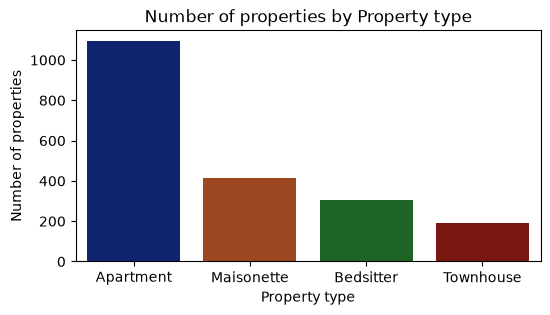

In [4]:
# Count of properties by property type  
plt.figure(figsize=(6, 3))  


sns.countplot(data=housing_df, x="property_type", palette="dark")  
plt.title("Number of properties by Property type")
plt.xlabel("Property type")
plt.ylabel("Number of properties")
# plt.xticks(rotation=45)

plt.show()

/var/folders/fh/dnmx2fzs5w16_qp8qtg223480000gn/T/ipykernel_3432/3936541289.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(housing_df, x="vacancy_status", palette="bright")


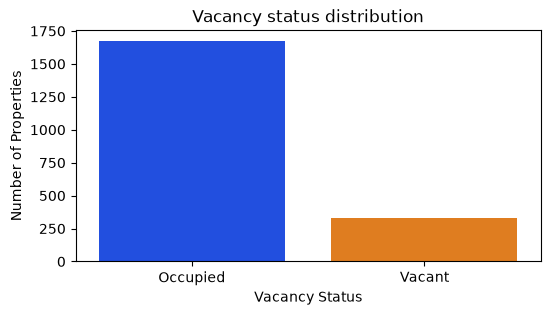

In [5]:
# Count of vacant vs occupied properties(vacancy status column)  
plt.figure(figsize=(6, 3))  

sns.countplot(housing_df, x="vacancy_status", palette="bright")
plt.xlabel("Vacancy Status")
plt.ylabel("Number of Properties")
plt.title("Vacancy status distribution")
plt.show()

__b) Bar Plots__  
Use bar plots when comparing aggregated values. e.g average rent.  

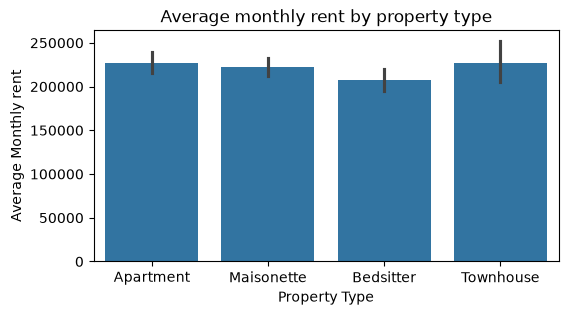

In [6]:
# Average monthly rent by property type  
plt.figure(figsize=(6, 3))  

sns.barplot(data=housing_df, x="property_type", y="monthly_rent_kes", estimator="mean")
plt.title("Average monthly rent by property type")
plt.xlabel("Property Type")
plt.ylabel("Average Monthly rent")

plt.show()

/var/folders/fh/dnmx2fzs5w16_qp8qtg223480000gn/T/ipykernel_3432/3862178246.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=housing_df, x="property_type", y="satisfaction_score", estimator="median",


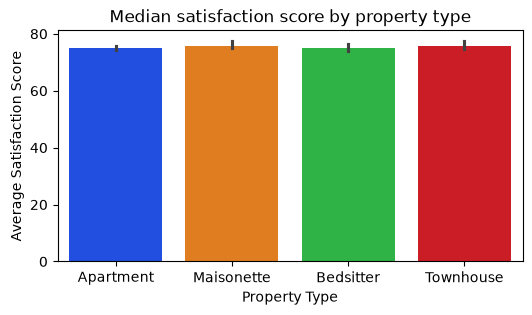

In [7]:
# Median satisfaction score by property trype  
plt.figure(figsize=(6, 3))

sns.barplot(data=housing_df, x="property_type", y="satisfaction_score", estimator="median",
           palette="bright")

plt.title("Median satisfaction score by property type")
plt.xlabel("Property Type")
plt.ylabel("Average Satisfaction Score")
plt.show()


__c) Histograms__   
Use histograms to show the distribution of a numerical column.  

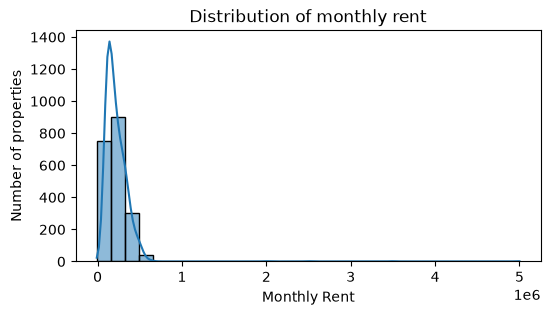

In [8]:
# Distribution of monthly rent  
plt.figure(figsize=(6, 3))  

sns.histplot(housing_df, x="monthly_rent_kes", bins=30, kde=True)
plt.xlabel("Monthly Rent")
plt.title("Distribution of monthly rent")  
plt.ylabel("Number of properties")
plt.show()

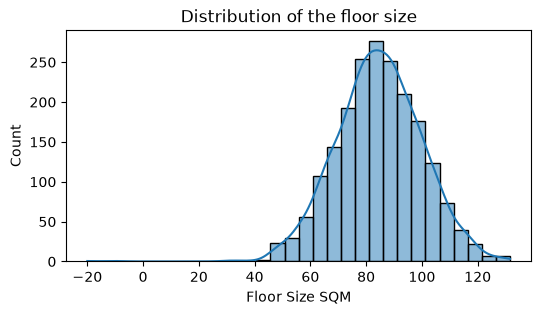

In [9]:
# Distribution of the floor size  
plt.figure(figsize=(6, 3))  

sns.histplot(data=housing_df, x="floor_size_sqm", bins=30, kde=True)
plt.title("Distribution of the floor size")
plt.xlabel("Floor Size SQM")
plt.show()

__d). Boxplot__  
Use a boxplot to compare spread, medain and outliers.   
_Example_   

![Boxplot explanation](https://doc.esri.com/en/arcgis-pro/latest/help/analysis/geoprocessing/charts/images/Box_Plot_Anatomy-996A7.png)

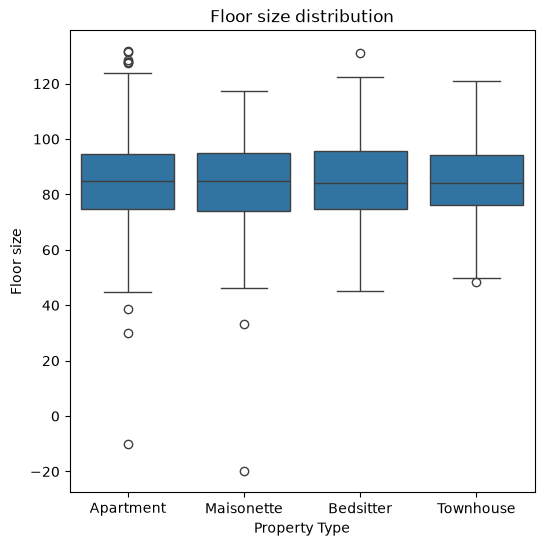

In [10]:
# Floor size  vs property type
plt.figure(figsize=(6, 6))

sns.boxplot(data=housing_df, x="property_type", y="floor_size_sqm")

plt.title("Floor size distribution")
plt.ylabel("Floor size")
plt.xlabel("Property Type")
plt.show()

In [11]:
# Step 1: Compute Q1,  Q3, IQR 
Q1 = housing_df["floor_size_sqm"].quantile(0.25)
Q3 = housing_df["floor_size_sqm"].quantile(0.75)

IQR = Q3 - Q1  

# Step 2: Define boundaries
lower_bound = Q1 - (1.5 * IQR)  
upper_bound = Q3 + (1.5 * IQR)

print("Quarter 1:", Q1, "\nQuarter 3:", Q3, "\n Interqartile range", IQR, "\n Minimum", lower_bound,"\n Maximum", upper_bound)  

# Step 3: Filter and display  
outliers = housing_df[(housing_df["floor_size_sqm"] < lower_bound) | 
                      (housing_df["floor_size_sqm"] > upper_bound)]   

print(display(outliers))

Quarter 1: 74.6 
Quarter 3: 94.9 
 Interqartile range 20.30000000000001 
 Minimum 44.14999999999998 
 Maximum 125.35000000000002


,property_id,estate,property_type,furnishing,bedrooms,bathrooms,floor_size_sqm,monthly_rent_kes,service_charge_kes,distance_to_cbd_km,...,security_rating,occupancy_rate,parking_slots,has_backup_generator,has_borehole,tenant_type,vacancy_status,satisfaction_score,rent_2024,rent_2025
302,303,Ruaka,Maisonette,Unfurnished,1,1,33.2,105507.0,4616.0,1.4,...,9.2,89.3,2,No,Yes,Family,Occupied,74.9,92015.0,105507.0
391,392,Kilimani,Maisonette,Unfurnished,6,6,-20.0,303460.0,9636.0,10.7,...,6.0,97.0,3,Yes,No,Family,Occupied,83.2,272662.0,303460.0
633,634,South B,Apartment,Semi-Furnished,2,1,38.5,98322.0,8237.0,12.2,...,7.2,96.1,2,No,No,Professional,Occupied,65.2,89231.0,98322.0
693,694,Embakasi,Apartment,Semi-Furnished,2,3,127.8,130640.0,886.0,6.8,...,7.6,87.2,2,No,Yes,Professional,Occupied,80.6,120519.0,130640.0
850,851,South C,Apartment,Unfurnished,4,4,131.6,222415.0,4145.0,1.7,...,8.1,91.4,2,Yes,Yes,Expat,Occupied,84.6,197112.0,222415.0
969,970,Westlands,Apartment,Furnished,6,5,127.5,496500.0,3452.0,6.2,...,7.5,93.6,4,No,Yes,Student,Occupied,73.3,451227.0,496500.0
1060,1061,South C,Apartment,Unfurnished,3,3,131.3,195864.0,4819.0,15.0,...,7.9,88.0,1,No,No,Family,Occupied,60.4,175439.0,195864.0
1135,1136,Langata,Apartment,Unfurnished,2,1,30.0,123444.0,6963.0,6.5,...,9.3,73.1,1,No,Yes,Professional,Occupied,79.0,108364.0,123444.0
1231,1232,Kasarani,Bedsitter,Unfurnished,3,4,131.0,160371.0,31495.0,3.6,...,9.2,85.9,2,Yes,No,Expat,Occupied,63.5,146100.0,160371.0
1238,1239,Lavington,Apartment,Unfurnished,1,1,128.4,304339.0,8943.0,23.0,...,7.0,99.2,1,Yes,No,Student,Occupied,77.0,277970.0,304339.0


None


__e) Scatter plots__   
Use a scatterplot to show the relationship between two numerical variables.  

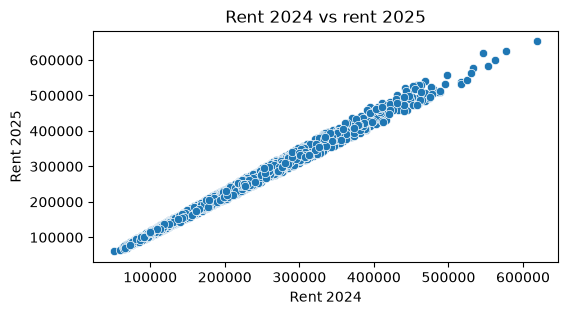

In [12]:
# Rent 2024 vs Rent 2025
plt.figure(figsize=(6, 3))  

sns.scatterplot(data=housing_df, x="rent_2024", y="rent_2025")
plt.title("Rent 2024 vs rent 2025")
plt.ylabel("Rent 2025")
plt.xlabel("Rent 2024")
plt.show()

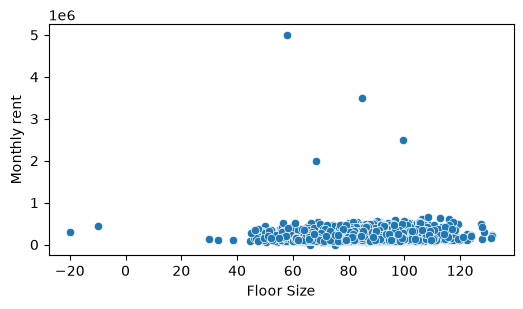

In [13]:
# Floor size vs monthly rent  
plt.figure(figsize=(6, 3))  

sns.scatterplot(data=housing_df, x="floor_size_sqm", y="monthly_rent_kes")  
plt.xlabel("Floor Size")
plt.ylabel("Monthly rent")  
plt.show()

__f). Lineplot__  
Line plots are best for showing trends.  

Before: 
       index            0
0  rent_2024  197121.7450
1  rent_2025  217312.5415
After: 
        year  average_rent
0  rent_2024   197121.7450
1  rent_2025   217312.5415


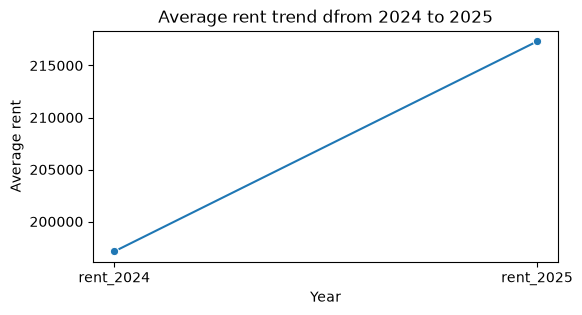

In [14]:
# Average rent trend from 2024 to 2025  
rent_trend = housing_df[["rent_2024", "rent_2025"]].mean().reset_index() 
print(f"Before: \n{rent_trend}")  

rent_trend.columns = ["year", "average_rent"]
print(f"After: \n{rent_trend}")  


plt.figure(figsize=(6, 3))  
sns.lineplot(data=rent_trend, x="year", y="average_rent", marker="o")

plt.title("Average rent trend dfrom 2024 to 2025")
plt.xlabel("Year")
plt.ylabel("Average rent")
plt.show()

__g). Pie Charts__   
Seaborn cannot directly create pie charts, so we use matplotlib.  

furnishing
Unfurnished       1007
Semi-Furnished     603
Furnished          390
Name: count, dtype: int64
Index(['Unfurnished', 'Semi-Furnished', 'Furnished'], dtype='str', name='furnishing')


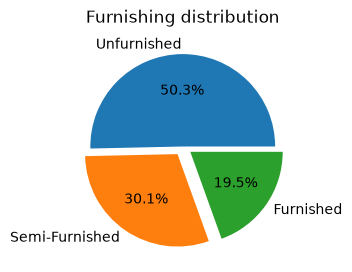

In [15]:
# Pie chart for furnishing status  
furnishing_count = housing_df["furnishing"].value_counts()

print(furnishing_count)  
print(furnishing_count.index)

explode = (0, 0.1, 0.1)

plt.figure(figsize=(6, 3))  
plt.pie(furnishing_count,explode=explode, labels=furnishing_count.index, autopct="%1.1f%%")
plt.title("Furnishing distribution")  
plt.show()

Index(['Occupied', 'Vacant'], dtype='str', name='vacancy_status')


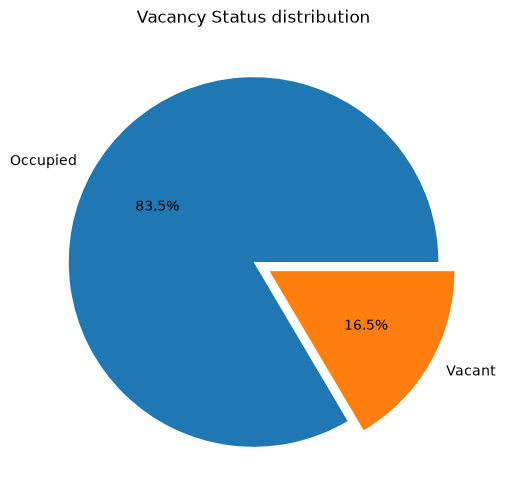

In [16]:
# Pie chart for the vacancy status  
vacancy_counts = housing_df["vacancy_status"].value_counts() 

print(vacancy_counts.index)

explode = (0, 0.1)

plt.figure(figsize=(10, 6))  
plt.pie(vacancy_counts, explode=explode, labels=vacancy_counts.index, autopct="%1.1f%%")
plt.title("Vacancy Status distribution")
plt.show()

__h). Heatmaps__   
Use heatmaps to show relationships between numerical variables(correlation between numerical variables).   

_Correlation Scale_  
-1      ----------------------------   0 ---------------------------------- 1    
strong -ve corr.....................No correlation........................ Strong positive correlation  

- -1 to -0.5 > Strong negative correlation   
- -0.5 to 0 > weak negative correlation  
- 0 > No correlation  
- 0 to 0.5 > weak positive correlation  
- 0.5 to 1 > Strong positive correlation  


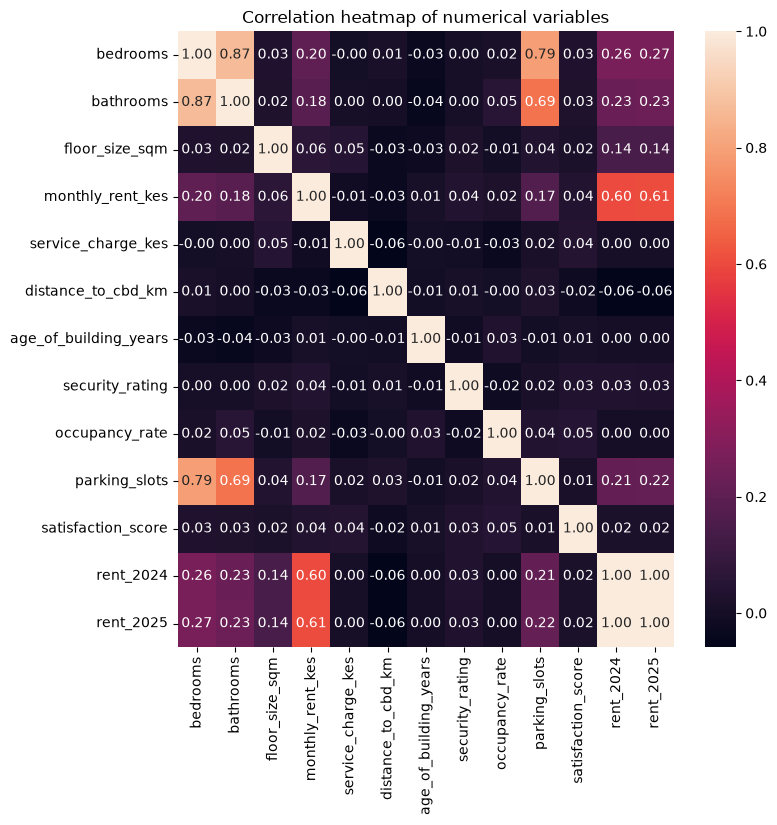

In [17]:
# Correlation heatmap for numerical columns  
# Select numerical columnsw from the dataset  
numerical_cols = housing_df.select_dtypes(include=["int", "float"]).columns.to_list()  

numerical_cols

numerical_cols.remove("property_id")

# Get the correlation  
correlation = housing_df[numerical_cols].corr()  

# Plot the heatmap  
plt.figure(figsize=(8, 8))  

sns.heatmap(correlation, annot=True, fmt=".2f")
plt.title("Correlation heatmap of numerical variables")    
plt.show()

- Reasearch on Univariate Analysis, Bivariate Analysis, Multivariate Analysis

In [18]:
housing_df.head()

,property_id,estate,property_type,furnishing,bedrooms,bathrooms,floor_size_sqm,monthly_rent_kes,service_charge_kes,distance_to_cbd_km,...,security_rating,occupancy_rate,parking_slots,has_backup_generator,has_borehole,tenant_type,vacancy_status,satisfaction_score,rent_2024,rent_2025
0,1,South B,Apartment,Unfurnished,3,2,114.8,174906.0,5549.0,9.9,...,6.5,93.5,2,Yes,No,Professional,Occupied,71.2,153825.0,174906.0
1,2,Karen,Apartment,Semi-Furnished,5,5,75.2,377170.0,3205.0,24.5,...,6.9,94.0,3,No,Yes,Professional,Occupied,89.4,336858.0,377170.0
2,3,Umoja,Apartment,Furnished,1,1,84.9,84013.0,4526.0,6.6,...,7.9,91.2,0,No,No,Student,Occupied,83.1,71889.0,84013.0
3,4,Ruaka,Apartment,Unfurnished,2,3,75.2,151752.0,2496.0,17.9,...,6.6,98.6,2,No,Yes,Student,Occupied,65.4,137138.0,151752.0
4,5,Kasarani,Maisonette,Unfurnished,3,3,69.6,98368.0,999.0,3.6,...,6.9,94.0,2,No,No,Expat,Occupied,70.8,91765.0,98368.0


## Univariate, Bivariate and Multivariate analysis. 
### 1. Univariate analysis. 
- Univariate analysis examines(visaulize) one variable at a time. 
- It's used to understand distribution, frequency or central tendency.  


_i) Categorical Features_

/var/folders/fh/dnmx2fzs5w16_qp8qtg223480000gn/T/ipykernel_3432/3208492032.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=housing_df, x="estate", palette="bright")


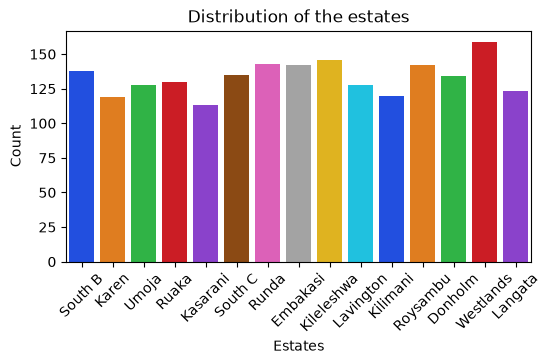

In [21]:
# Distribution of the estate column. 
plt.figure(figsize=(6, 3))

sns.countplot(data=housing_df, x="estate", palette="bright")
plt.title("Distribution of the estates")
plt.xlabel("Estates")
plt.ylabel("Count")
plt.xticks(rotation=45)
plt.show()

_ii). Numerical columns_


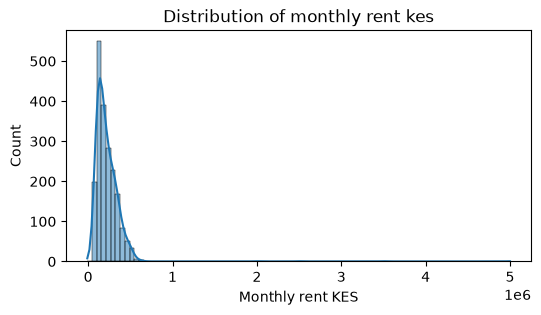

In [23]:
# Distribution of monthly rent. 
plt.figure(figsize=(6, 3))

sns.histplot(data=housing_df, x="monthly_rent_kes", kde=True)
plt.title("Distribution of monthly rent kes")
plt.xlabel("Monthly rent KES")
plt.show()


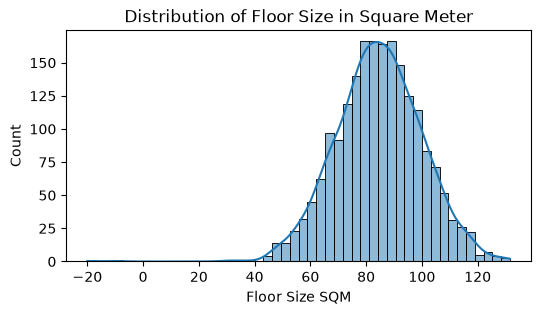

In [24]:
# (Normal Distribution) Distribution of the Floor Size. 
plt.figure(figsize=(6, 3))

sns.histplot(data=housing_df, x="floor_size_sqm", kde=True)
plt.title("Distribution of Floor Size in Square Meter")
plt.xlabel("Floor Size SQM")
plt.show()

### 2. Bivariate Analysis. 
Bivariate analysis studies the relationship between two variables.   

_i). Numerical Features_


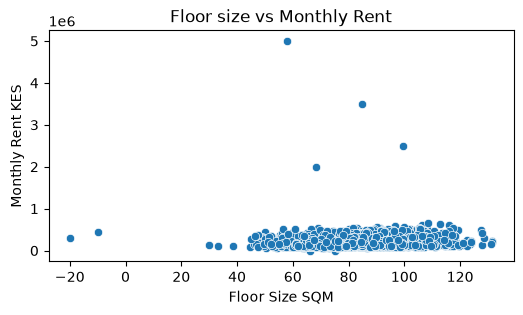

In [35]:
# Floor Size vs Monthly rent. 
plt.figure(figsize=(6, 3))

sns.scatterplot(data=housing_df, x="floor_size_sqm", y="monthly_rent_kes")

plt.title("Floor size vs Monthly Rent")
plt.xlabel("Floor Size SQM")
plt.ylabel("Monthly Rent KES")
plt.show()

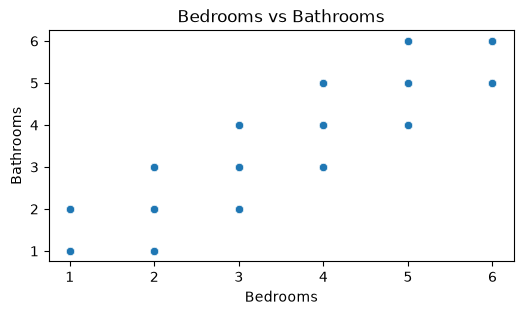

In [36]:
# Number of Bedrooms vs Bathrooms

plt.figure(figsize=(6, 3))

sns.scatterplot(data=housing_df, x="bedrooms", y="bathrooms")
plt.title("Bedrooms vs Bathrooms")
plt.xlabel("Bedrooms")
plt.ylabel("Bathrooms")
plt.show()

_ii). Categorical vs Numerical_

/var/folders/fh/dnmx2fzs5w16_qp8qtg223480000gn/T/ipykernel_3432/2639993859.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=housing_df, x="estate", y="monthly_rent_kes", estimator="mean", palette="bright")


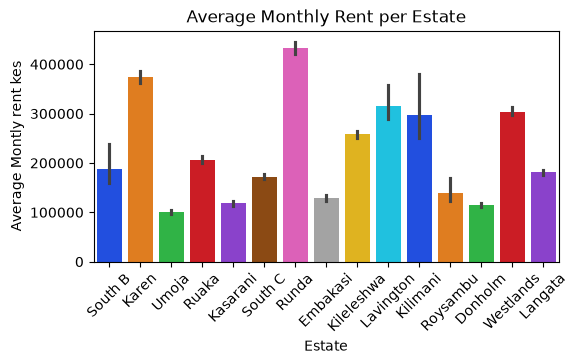

In [37]:
# Plot a barplot of average monthly rent per estate
plt.figure(figsize=(6, 3))

sns.barplot(data=housing_df, x="estate", y="monthly_rent_kes", estimator="mean", palette="bright")
plt.title("Average Monthly Rent per Estate")
plt.xlabel("Estate")
plt.ylabel("Average Montly rent kes")
plt.xticks(rotation=45)
plt.show()

_iii). Categorical vs Categorical_

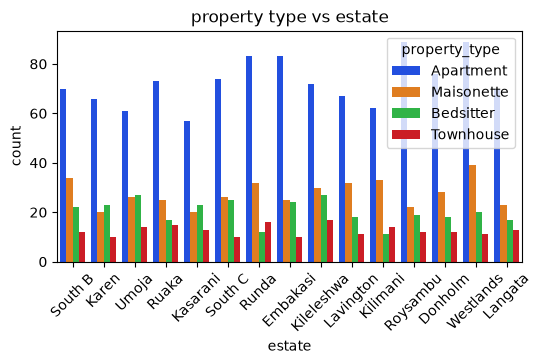

In [42]:
# Plot property_types in various estates. 
plt.figure(figsize=(6, 3))

sns.countplot(data=housing_df, x="estate", hue="property_type", palette="bright")
plt.title("property type vs estate")
plt.xlabel("estate")
plt.xticks(rotation=45)
plt.show()

### 3. Multivariate Analysis. 
- Multivariate analysis examines relationships among three or more variables.  

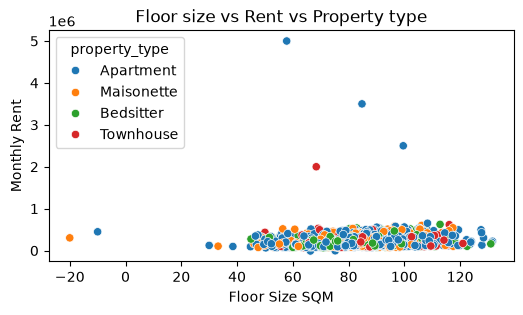

In [44]:
# Floor size vs Monthly rent vs property type. 
plt.figure(figsize=(6, 3)) 

sns.scatterplot(data= housing_df, x="floor_size_sqm", y='monthly_rent_kes', hue='property_type')
plt.title("Floor size vs Rent vs Property type")
plt.xlabel("Floor Size SQM")
plt.ylabel("Monthly Rent")
plt.show()


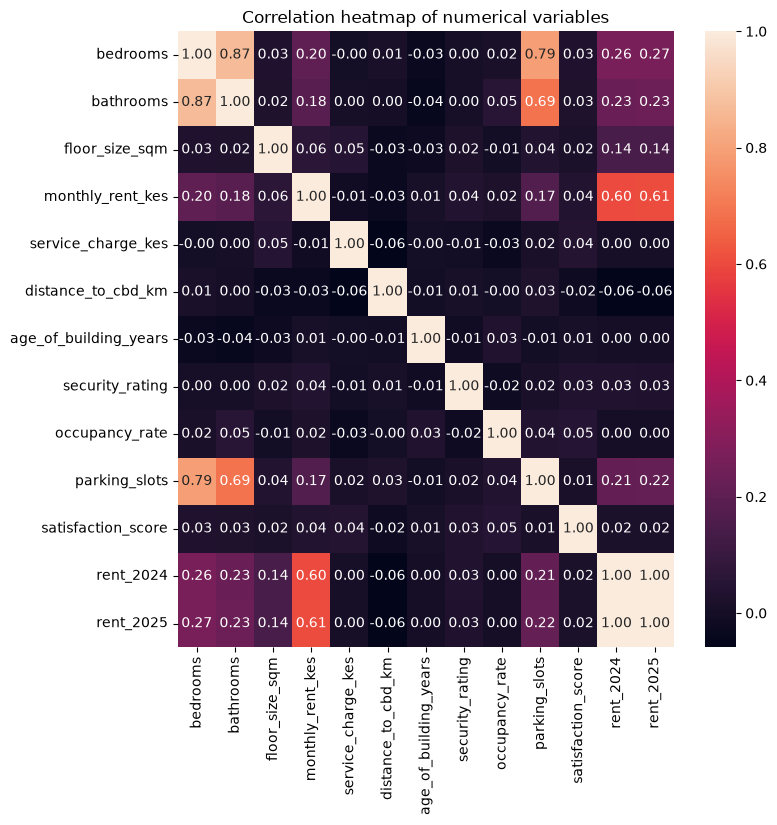

In [45]:
# Correlation heatmap for numerical columns  
# Select numerical columnsw from the dataset  
numerical_cols = housing_df.select_dtypes(include=["int", "float"]).columns.to_list()  

numerical_cols

numerical_cols.remove("property_id")

# Get the correlation  
correlation = housing_df[numerical_cols].corr()  

# Plot the heatmap  
plt.figure(figsize=(8, 8))  

sns.heatmap(correlation, annot=True, fmt=".2f")
plt.title("Correlation heatmap of numerical variables")    
plt.show()

In [39]:
housing_df.head()

,property_id,estate,property_type,furnishing,bedrooms,bathrooms,floor_size_sqm,monthly_rent_kes,service_charge_kes,distance_to_cbd_km,...,security_rating,occupancy_rate,parking_slots,has_backup_generator,has_borehole,tenant_type,vacancy_status,satisfaction_score,rent_2024,rent_2025
0,1,South B,Apartment,Unfurnished,3,2,114.8,174906.0,5549.0,9.9,...,6.5,93.5,2,Yes,No,Professional,Occupied,71.2,153825.0,174906.0
1,2,Karen,Apartment,Semi-Furnished,5,5,75.2,377170.0,3205.0,24.5,...,6.9,94.0,3,No,Yes,Professional,Occupied,89.4,336858.0,377170.0
2,3,Umoja,Apartment,Furnished,1,1,84.9,84013.0,4526.0,6.6,...,7.9,91.2,0,No,No,Student,Occupied,83.1,71889.0,84013.0
3,4,Ruaka,Apartment,Unfurnished,2,3,75.2,151752.0,2496.0,17.9,...,6.6,98.6,2,No,Yes,Student,Occupied,65.4,137138.0,151752.0
4,5,Kasarani,Maisonette,Unfurnished,3,3,69.6,98368.0,999.0,3.6,...,6.9,94.0,2,No,No,Expat,Occupied,70.8,91765.0,98368.0
